# CSE 5104 - FL26 Project 1: Concrete Compressive Strength Analysis

**Group Members:** Lauren Lal, Emily Iorio, Katherine Feng  

In [2]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

### **Part 1: Programming & Algorithm Implementation**

In [4]:
## Import Data
df = pd.read_excel('data/Concrete_Data.xls', engine='xlrd')

df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


## **Gradient Descent from Scratch**
Implement a gradient descent optimization algorithm using MSE as the objective function.  

Codebase must support both univariate models (y=mx+b) and multivariate models (input x, vector of length p, p+1 parameters). 

Evaluate all models using both MSE and variance explained R^2 = 1 - MSE / Variance(observed)

**Note: The notebook requires `gradient_descent.py` to run, and is implemented below.**

In [5]:
from gradient_descent import gradient_descent, evaluate

## **Data Analysis** 

## Use the implemented algorithm, a third-part linear model optimization tool, and a third-party statistical tool for the following.

In [6]:
#seperate testing and training
testing = df.iloc[500:630]
training = pd.concat([df.iloc[:500], df.iloc[630:1030]])

print(df.columns)
print(len(training))
print(len(testing))

target = "Concrete compressive strength(MPa, megapascals) "

X_train = training.drop(columns=[target])
y_train = training[target]

X_test = testing.drop(columns=[target])
y_test = testing[target]

Index(['Cement (component 1)(kg in a m^3 mixture)',
       'Blast Furnace Slag (component 2)(kg in a m^3 mixture)',
       'Fly Ash (component 3)(kg in a m^3 mixture)',
       'Water  (component 4)(kg in a m^3 mixture)',
       'Superplasticizer (component 5)(kg in a m^3 mixture)',
       'Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
       'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)',
       'Concrete compressive strength(MPa, megapascals) '],
      dtype='object')
900
130


In [7]:
X_train = X_train.to_numpy(dtype=float)
y_train = y_train.to_numpy(dtype=float)
X_test = X_test.to_numpy(dtype=float)
y_test = y_test.to_numpy(dtype=float)

In [8]:
# Descriptive statistics for the training dataset
descriptive_stats = training.describe().T[
    ["mean", "std", "min", "max"]
].round(2)

descriptive_stats = descriptive_stats.rename(columns={
    "mean": "Mean",
    "std": "Std. Dev.",
    "min": "Minimum",
    "max": "Maximum"
})

descriptive_stats

,Mean,Std. Dev.,Minimum,Maximum
Cement (component 1)(kg in a m^3 mixture),277.87,106.00,102.00,540.0
Blast Furnace Slag (component 2)(kg in a m^3 mixture),76.11,84.07,0.00,305.3
Fly Ash (component 3)(kg in a m^3 mixture),57.38,64.26,0.00,200.1
Water (component 4)(kg in a m^3 mixture),180.72,22.28,121.75,247.0
Superplasticizer (component 5)(kg in a m^3 mixture),6.86,5.98,0.00,32.2
Coarse Aggregate (component 6)(kg in a m^3 mixture),973.76,77.57,801.00,1145.0
Fine Aggregate (component 7)(kg in a m^3 mixture),772.33,81.91,594.00,992.6
Age (day),46.04,61.32,1.00,365.0
"Concrete compressive strength(MPa, megapascals)",36.93,16.65,2.33,82.6


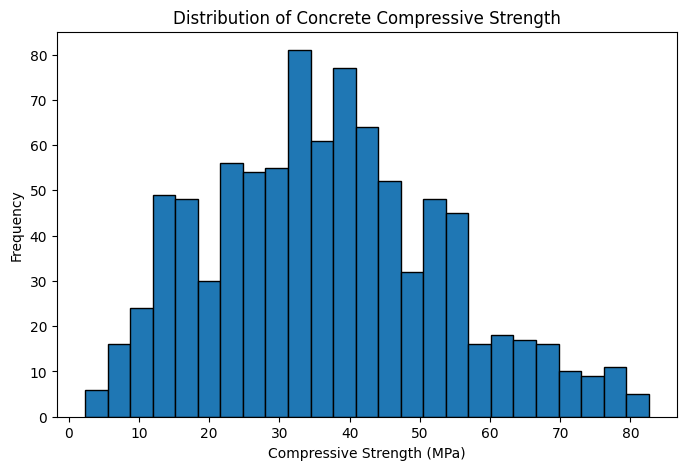

In [16]:
# Distribution of measured compressive strength
plt.figure(figsize=(8, 5))

plt.hist(
    training[target],
    bins=25,
    edgecolor="black"
)

plt.xlabel("Compressive Strength (MPa)")
plt.ylabel("Frequency")
plt.title("Distribution of Concrete Compressive Strength")
plt.grid(axis="y", alpha=0.0)
##plt.tight_layout()
plt.show()

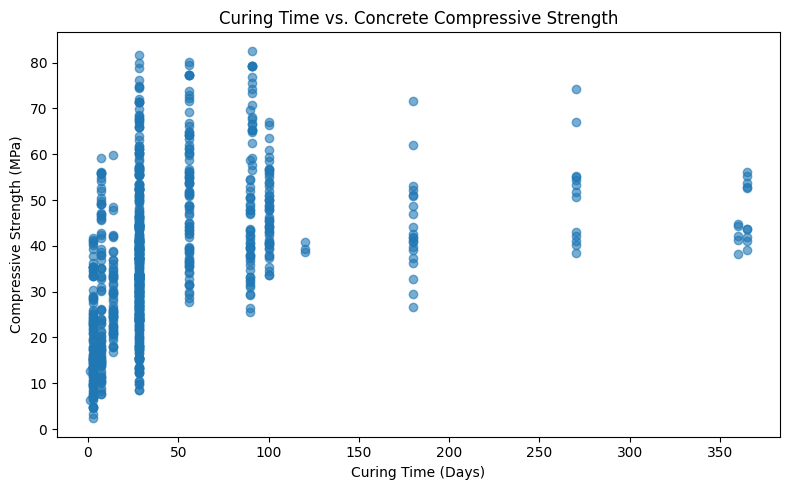

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(
    training["Age (day)"],
    training[target],
    alpha=0.6
)

plt.xlabel("Curing Time (Days)")
plt.ylabel("Compressive Strength (MPa)")
plt.title("Curing Time vs. Concrete Compressive Strength")
plt.grid(True, alpha=0.0)
plt.tight_layout()
plt.show()

## **Untransformed Features**

In [6]:
learning_rates= [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]

for lr in learning_rates:
    weights, bias, loss = gradient_descent(X_train, y_train, learning_rate=lr, tolerance=1e-6)
    print(f"Learning Rate: {lr}")
    mse, r2 = evaluate(X_test, y_test, weights, bias)
    print(f"MSE: {mse}, R2: {r2}")

Learning Rate: 1e-08
MSE: 224.6401600702936, R2: -0.0038937200947559703
Learning Rate: 1e-07
MSE: 141.7513929888169, R2: 0.36652763605747063
Learning Rate: 1e-06
MSE: 6.725831831721794e+305, R2: -3.00570491766303e+303
Learning Rate: 1e-05
MSE: inf, R2: -inf
Learning Rate: 0.0001
MSE: 6.647200720847729e+305, R2: -2.9705654847202085e+303
Learning Rate: 0.001
MSE: inf, R2: -inf
Learning Rate: 0.01
MSE: inf, R2: -inf


/Users/laurenlal/CSE5140/cse5104-project1/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/Users/laurenlal/CSE5140/cse5104-project1/gradient_descent.py:19: RuntimeWarning: overflow encountered in square
  mse = np.mean(errors ** 2)
/Users/laurenlal/CSE5140/cse5104-project1/gradient_descent.py:45: RuntimeWarning: overflow encountered in square
  mse = np.mean((y-y_pred) ** 2)


We will choose learning rate $\alpha = $ 1e-07

In [7]:
weights_unscaled, bias_unscaled, loss_unscaled = gradient_descent(
    X_train,
    y_train,
    learning_rate=1e-7,
    tolerance=1e-6
)

mse_unscaled, r2_unscaled = evaluate(
    X_test,
    y_test,
    weights_unscaled,
    bias_unscaled
)

print(f"MSE: {mse_unscaled}, R2: {r2_unscaled}")

MSE: 141.7513929888169, R2: 0.36652763605747063


## **Standarized/Normalized Features**

In [8]:
#Standardize the features
training_mean = X_train.mean(axis=0)
training_std = X_train.std(axis=0)

X_train_std = (X_train - training_mean) / training_std
X_test_std = (X_test - training_mean) / training_std

In [9]:
learning_rates= [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]

for lr in learning_rates:
    weights, bias, loss = gradient_descent(X_train_std, y_train, learning_rate=lr, tolerance=1e-6)
    print(f"Learning Rate: {lr}")
    mse, r2 = evaluate(X_test_std, y_test, weights, bias)
    print(f"MSE: {mse}, R2: {r2}")


Learning Rate: 1e-08
MSE: 1015.2115777870446, R2: -3.536875896050775
Learning Rate: 1e-07
MSE: 1011.3935862715739, R2: -3.5198136855156834
Learning Rate: 1e-06
MSE: 974.0367607471388, R2: -3.3528698828807455
Learning Rate: 1e-05
MSE: 672.0720785687311, R2: -2.0034208438734074
Learning Rate: 0.0001
MSE: 104.16247912669178, R2: 0.5345086175505488
Learning Rate: 0.001
MSE: 133.3949577842348, R2: 0.40387168362952386
Learning Rate: 0.01
MSE: 141.08573604288478, R2: 0.3695023883348443


We will choose learning rate $\alpha = 0.0001$

In [10]:
weights_scaled, bias_scaled, loss_scaled = gradient_descent(
    X_train_std,
    y_train,
    learning_rate=0.0001,
    tolerance=1e-6
)

mse_scaled, r2_scaled = evaluate(
    X_test_std,
    y_test,
    weights_scaled,
    bias_scaled
)

print(f"MSE: {mse_scaled}, R2: {r2_scaled}")

MSE: 104.16247912669178, R2: 0.5345086175505488


## Provide a figure showing loss over iterations for both

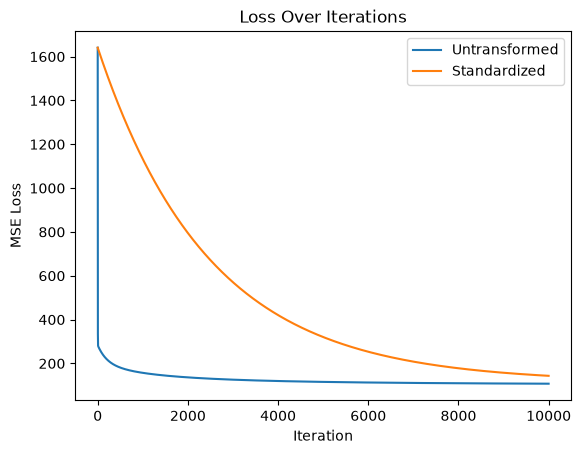

In [11]:
plt.figure()

plt.plot(loss_unscaled, label="Untransformed")
plt.plot(loss_scaled, label="Standardized")

plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.title("Loss Over Iterations")
plt.legend()
plt.show()

## How does feature scaling affect convergence speed and stability? Explain why.

Feature scaling improves the stability of gradient descent by allowing a larger learning rate to be used. Without feature scaling, we had to use a learning rate of 1e-07 to prevent overshooting, but that means that learning everywhere else flattens out. After standardizing the features, we could use a much larger learning rate of 0.0001 to maintain stable convergence and achive a positive r2. 

This happens because the original features have different numerical scales, which causes the gradients for different features to have different sizes. A learning rate that works for one feature might be too large for another, causing the gradient descent to overshoot and become unstable. Standardization puts the features on comparable scales, making the gradient updates more balanced and allowing larger learning rates to be used safely.

## **Scaling & The Optimal Solution**  
Use the external linear model optimization tool to find the optimal solution for an untransformed multivariate model and a scaled multivariate model.  

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

## **Untransformed Multivariate Model**

In [13]:
model = LinearRegression()
model.fit(X_train, y_train)

#get predictions 
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

#evaluate model 
train_mse = np.mean((y_train - y_train_pred) ** 2)
train_r2 = 1 - train_mse / np.var(y_train)
test_mse = np.mean((y_test - y_test_pred) ** 2)
test_r2 = 1 - test_mse / np.var(y_test)

print(f"Train MSE: {train_mse}, Train R2: {train_r2}")
print(f"Test MSE: {test_mse}, Test R2: {test_r2}")

Train MSE: 104.14373897310757, Train R2: 0.6240495572262079
Test MSE: 141.31386470838999, Test R2: 0.36848290484354596


## **Scaled Multivariate Model**

In [14]:
#scale the data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [15]:
#fit the model
scaled_model = LinearRegression()
scaled_model.fit(X_train_scaled, y_train)

y_train_scaled_pred = scaled_model.predict(X_train_scaled)
y_test_scaled_pred = scaled_model.predict(X_test_scaled)

In [16]:
train_mse_scaled = np.mean((y_train - y_train_scaled_pred) ** 2)
train_r2_scaled = 1 - train_mse_scaled / np.var(y_train)

test_mse_scaled = np.mean((y_test - y_test_scaled_pred) ** 2)
test_r2_scaled = 1 - test_mse_scaled / np.var(y_test)

print(f"Train MSE (Scaled): {train_mse_scaled}, Train R2 (Scaled): {train_r2_scaled}")
print(f"Test MSE (Scaled): {test_mse_scaled}, Test R2 (Scaled): {test_r2_scaled}")

Train MSE (Scaled): 104.14373897310753, Train R2 (Scaled): 0.6240495572262081
Test MSE (Scaled): 141.31386470839004, Test R2 (Scaled): 0.36848290484354573


## Does a linear transformation meaningfully change the optimal mathematical solution?

No, a linear transformation does not change the optimal math solution because standaridization/other linear transformation techniques only change the scale of the features, not the actual linear relationship between the features and target variable. Even though the actual values are different, they are just scaled so the patterns and relationships remain the same and have the same predictions and underlying model. That's why the MSE and the R2 were the same between the scaled and unscaled data.

## **Non-Linear Transformations:**  

Apply a logarithmic transformation, log(𝑥 + 1), to your features and use your gradient descent implementation to train a new multivariate model. 

In [17]:
#transform via log 
X_train_log = np.log(X_train + 1)
X_test_log = np.log(X_test + 1)

print(X_train_log)

[[6.29341928 0.         0.         ... 6.94793707 6.51767127 3.36729583]
 [6.29341928 0.         0.         ... 6.96224346 6.51767127 3.36729583]
 [5.80964287 4.96633504 0.         ... 6.8384052  6.38856141 5.60211882]
 ...
 [5.00729639 4.94449549 4.69683737 ... 6.79503441 6.66057515 3.36729583]
 [5.07579862 5.23484494 0.         ... 6.89831082 6.67190636 3.36729583]
 [5.56796275 4.6200588  4.37323813 ... 6.76330737 6.63660251 3.36729583]]


In [18]:
#run with gradient descent
learning_rates= [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]

for lr in learning_rates:
    weights, bias, loss = gradient_descent(X_train_log, y_train, learning_rate=lr, tolerance=1e-6)
    print(f"Learning Rate: {lr}")
    mse, r2 = evaluate(X_test_log, y_test, weights, bias)
    print(f"MSE: {mse}, R2: {r2}")

Learning Rate: 1e-08
MSE: 945.8685828761779, R2: -3.2269891994699025
Learning Rate: 1e-07
MSE: 517.8736422296289, R2: -1.3143239262037594
Learning Rate: 1e-06
MSE: 234.36315210340902, R2: -0.04734476927279063
Learning Rate: 1e-05
MSE: 238.68644888351713, R2: -0.06666513695013876
Learning Rate: 0.0001
MSE: 131.4382450817054, R2: 0.41261603100482946
Learning Rate: 0.001
MSE: 55.57164691236993, R2: 0.7516560381136022
Learning Rate: 0.01
MSE: 1.1712362155263202e+306, R2: -5.2341339195382284e+303


/Users/laurenlal/CSE5140/cse5104-project1/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


We will choose learning rate $\alpha = 0.001$

In [19]:
weights_log, bias_log, loss_log = gradient_descent(X_train_log, y_train, learning_rate=0.001, tolerance=1e-6)
log_mse, log_r2 = evaluate(X_test_log, y_test, weights_log, bias_log)
print(f"Log MSE: {log_mse}, Log R2: {log_r2}")

Log MSE: 55.57164691236993, Log R2: 0.7516560381136022


## Provide an updated figure showing loss over iterations. 

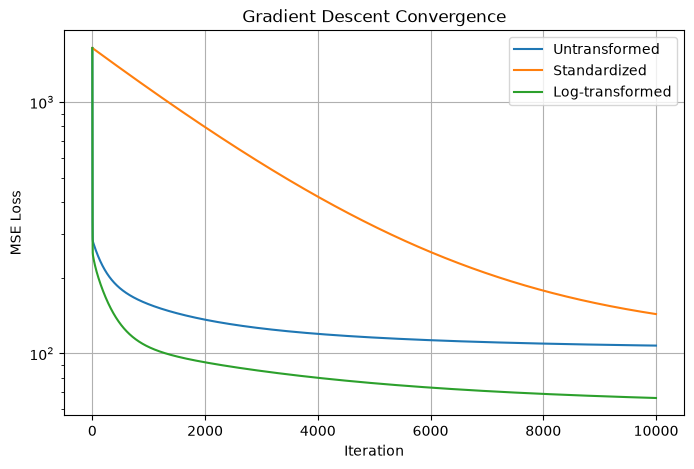

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(loss_unscaled, label="Untransformed")
plt.plot(loss_scaled, label="Standardized")
plt.plot(loss_log, label="Log-transformed")

plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.title("Gradient Descent Convergence")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()

## How does this non-linear feature transformation affect convergence speed and stability?

The non-linear transformation/log transformation improved the convergence speed and stability. The log transformation reduced the loss more quickly compared to the standardized data and stabalized more quickly compared to the untransformed data. This is due to the fact that log transformations compress large values which allows the optimization process to be more stable. Log transformation also changes the relationship between the features and target variables away from linear relationships unlike standardization techniques, which allows the model to achieve a lower loss based on a better fit relationship.

## Use an external linear model optimization tool to find the optimum solution for a logarithmically transformed multivariate model.

In [21]:
log_model = LinearRegression()
log_model.fit(X_train_log, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[23.62, 2.3 , 0.2 ,..., 4.19,-6.65, 9.03]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,81
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,8
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[82.18,64.43,32.91,..., 3.25, 2.75, 1.12]"


In [22]:
y_train_log = log_model.predict(X_train_log)
y_test_log = log_model.predict(X_test_log)

In [23]:
train_log_mse = np.mean((y_train - y_train_log) ** 2)
train_log_r2 = 1 - train_log_mse / np.var(y_train)

test_log_mse = np.mean((y_test - y_test_log) ** 2)
test_log_r2 = 1 - test_log_mse / np.var(y_test)

print(f"Train Log MSE: {train_log_mse}, Train Log R2: {train_log_r2}")
print(f"Test Log MSE: {test_log_mse}, Test Log R2: {test_log_r2}")

Train Log MSE: 55.83241823500241, Train Log R2: 0.798449502931704
Test Log MSE: 54.38490724351376, Test Log R2: 0.7569594553680202


## Construct a summary table comparing Training MSE, Testing MSE, Training R^2, and Testing R^2 across the 3 optimal models: Untransformed, Standardized/Normalized, and Log-Transformed.

In [24]:
summary_table = pd.DataFrame({
    "Model": [
        "Untransformed",
        "Standardized/Normalized",
        "Log-Transformed"
    ],
    "Training MSE": [
        train_mse,
        train_mse_scaled,
        train_log_mse
    ],
    "Testing MSE": [
        test_mse,
        test_mse_scaled,
        test_log_mse
    ],
    "Training R^2": [
        train_r2,
        train_r2_scaled,
        train_log_r2
    ],
    "Testing R^2": [
        test_r2,
        test_r2_scaled,
        test_log_r2
    ]
})

summary_table.round(3)

,Model,Training MSE,Testing MSE,Training R^2,Testing R^2
0,Untransformed,104.144,141.314,0.624,0.368
1,Standardized/Normalized,104.144,141.314,0.624,0.368
2,Log-Transformed,55.832,54.385,0.798,0.757


## How does a non-linear transformation differ from a linear transformation in its impact on the optimal model solution and overall predictive performance? Explain why.

As stated above, a linear transformation does not meaningfully impact the optimal model solution because it only changes the scale of the features, not the underlying relationship. This is why the Untransformed and standardized data have the same training and testing MSE and R-squared values. However, a non-linear transformation such as the log transformation we applied changes the relationship between the predictors and response, so the optimal coefficients and performance changes and can fit the prediction and real values better compared to the raw models. We can see this above because the MSE and R-squared all showed that the log model performed better than the untransformed and standardized models. The R-squared for training and testing was better for the log model, which means the log model explained the variability in the response better than the other 2 models.

## **Univariate vs Multivariate Coefficients:**  

## Use gradient descent implementation to train 8 separate univariate models for each untransformed predictor until we achieve a positive R^2. 

In [25]:
##get each of the 8 feature names
feature_names = training.drop(columns=[target]).columns.tolist()
print(feature_names)


learning_rates = [1e-3, 5e-4, 1e-4, 5e-5, 1e-5, 5e-6, 1e-6, 5e-7, 1e-7, 1e-8]
iterations = [10000, 30000, 50000]

['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)']


In [26]:
##code here
results = []
for i in range(len(feature_names)):

    X_train_uni = X_train[:, [i]]
    X_test_uni = X_test[:, [i]]
     
    for r in learning_rates:
        for it in iterations:
            w, b, loss = gradient_descent(X_train_uni, y_train, r, it)

            mse_train, r2_train = evaluate(X_train_uni, y_train, w, b)
            mse_test, r2_test = evaluate(X_test_uni, y_test, w, b)

            if np.isfinite(mse_train) and np.isfinite(r2_train):
                results.append({
                "predictor": feature_names[i],
                "learning_rate": r,
                "iterations": it,
                "iterations ran": len(loss),
                "coefficent": w[0],
                "bias": b,
                "mse_train": mse_train,
                "r2_train": r2_train,
                "mse_test": mse_test,
                "r2_test": r2_test
                })


/Users/laurenlal/CSE5140/cse5104-project1/gradient_descent.py:19: RuntimeWarning: overflow encountered in square
  mse = np.mean(errors ** 2)
/Users/laurenlal/CSE5140/cse5104-project1/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/Users/laurenlal/CSE5140/cse5104-project1/gradient_descent.py:45: RuntimeWarning: overflow encountered in square
  mse = np.mean((y-y_pred) ** 2)


In [27]:
results_df = pd.DataFrame(results)
best_results = (
    results_df.loc[
        results_df.groupby("predictor")["mse_train"].idxmin()
    ]
    .reset_index(drop=True)
)

best_results

,predictor,learning_rate,iterations,iterations ran,coefficent,bias,mse_train,r2_train,mse_test,r2_test
0,Age (day),0.000100,50000,50000,0.095636,32.488509,242.971475,0.122893,298.884958,-0.335686
1,Blast Furnace Slag (component 2)(kg in a m^3 m...,0.000050,50000,50000,0.044710,32.307627,272.658056,0.015727,301.969537,-0.349471
2,Cement (component 1)(kg in a m^3 mixture),0.000010,50000,50000,0.120857,1.726214,224.411965,0.189891,255.313040,-0.140968
3,Coarse Aggregate (component 6)(kg in a m^3 mi...,0.000001,50000,50000,0.037470,0.040077,297.945301,-0.075558,344.220371,-0.538285
4,Fine Aggregate (component 7)(kg in a m^3 mixture),0.000001,50000,50000,0.046855,0.067287,311.382662,-0.124066,333.111301,-0.488640
5,Fly Ash (component 3)(kg in a m^3 mixture),0.000100,50000,50000,-0.052215,39.837326,265.263721,0.042420,378.731383,-0.692512
6,Superplasticizer (component 5)(kg in a m^3 mix...,0.001000,30000,13212,0.888172,30.831750,248.818934,0.101784,197.723044,0.116396
7,Water (component 4)(kg in a m^3 mixture),0.000010,50000,50000,0.192165,1.104334,335.964008,-0.212803,330.990539,-0.479163


In [28]:
best_results

,predictor,learning_rate,iterations,iterations ran,coefficent,bias,mse_train,r2_train,mse_test,r2_test
0,Age (day),0.000100,50000,50000,0.095636,32.488509,242.971475,0.122893,298.884958,-0.335686
1,Blast Furnace Slag (component 2)(kg in a m^3 m...,0.000050,50000,50000,0.044710,32.307627,272.658056,0.015727,301.969537,-0.349471
2,Cement (component 1)(kg in a m^3 mixture),0.000010,50000,50000,0.120857,1.726214,224.411965,0.189891,255.313040,-0.140968
3,Coarse Aggregate (component 6)(kg in a m^3 mi...,0.000001,50000,50000,0.037470,0.040077,297.945301,-0.075558,344.220371,-0.538285
4,Fine Aggregate (component 7)(kg in a m^3 mixture),0.000001,50000,50000,0.046855,0.067287,311.382662,-0.124066,333.111301,-0.488640
5,Fly Ash (component 3)(kg in a m^3 mixture),0.000100,50000,50000,-0.052215,39.837326,265.263721,0.042420,378.731383,-0.692512
6,Superplasticizer (component 5)(kg in a m^3 mix...,0.001000,30000,13212,0.888172,30.831750,248.818934,0.101784,197.723044,0.116396
7,Water (component 4)(kg in a m^3 mixture),0.000010,50000,50000,0.192165,1.104334,335.964008,-0.212803,330.990539,-0.479163


## Which models were easy to train? Which models were hard?

Age, cement and superplasticizer were relatively easy to train because we were able to achieve a positive r^2 value with the training data. Particularly, cement used a lower amount of iterations to achieve the positive r^2 value compared to the other features, and superplasticizer was able to achieve a positive r^2 with a larger learning rate of 0.001. Fly Ash and Blast Furnace Slag also had a positive r^2 value, but it was much smaller and required many more iterations to achieve - indicating it was easy, but not as easy as age, cement, and superplasticizer. The models for Coarse Aggregate, Water, and Fine Aggregate Component were more difficult because they achieved negative r^2 values with the training data. Overall, models with smaller learning rates and a larger number of iterations were harder to optimize, while other models that converged with larger learning rates and small numbers of iterations were easier to optimize.


## Use an external linear model optimization tool to find the optimal solution for each of the univariate models.  Compare the individual coefficients from these univariate models to the corresponding feature weights found in the optimal untransformed multivariate model

In [29]:
##codehere
uni_coef = []

for i in range(len(feature_names)):
    X_uni = X_train[:, [i]]
    model_uni = LinearRegression()
    model_uni.fit(X_uni, y_train)
    uni_coef.append(float(model_uni.coef_[0]))


uni_coef


[0.08078373406661954,
 0.031598421871021805,
 -0.05340432082232581,
 -0.2070164882115821,
 0.8881414698064337,
 -0.027381579020319825,
 -0.030581653010551272,
 0.0952084133113395]

In [30]:
#multimodel
model_multi = LinearRegression()
model_multi.fit(X_train, y_train)
multi_coef = model_multi.coef_

multi_coef

array([ 0.13244887,  0.1247277 ,  0.10614715, -0.13410002,  0.11723871,
        0.02854652,  0.03383504,  0.11880428])

## Are they identical? Support your answer with a table of coefficients. 

The univariate and multivariate coefficients are not identical, and many coefficients have become larger or smaller or changed signs. For example, fly ash as a univariate coefficient is -0.05 but becomes 0.11 in the multivariate model. You can see below that all coefficients have changed.

In [31]:
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Univariate Coefficient": uni_coef,
    "Multivariate Coefficient": multi_coef
})

coef_df["Difference"] = (
    coef_df["Univariate Coefficient"]
    - coef_df["Multivariate Coefficient"]
)

coef_df

,Feature,Univariate Coefficient,Multivariate Coefficient,Difference
0,Cement (component 1)(kg in a m^3 mixture),0.080784,0.132449,-0.051665
1,Blast Furnace Slag (component 2)(kg in a m^3 m...,0.031598,0.124728,-0.093129
2,Fly Ash (component 3)(kg in a m^3 mixture),-0.053404,0.106147,-0.159551
3,Water (component 4)(kg in a m^3 mixture),-0.207016,-0.134100,-0.072916
4,Superplasticizer (component 5)(kg in a m^3 mix...,0.888141,0.117239,0.770903
5,Coarse Aggregate (component 6)(kg in a m^3 mi...,-0.027382,0.028547,-0.055928
6,Fine Aggregate (component 7)(kg in a m^3 mixture),-0.030582,0.033835,-0.064417
7,Age (day),0.095208,0.118804,-0.023596


## Why are univariate coefficients not equal to multivariate coefficients? Explain the roles of feature correlations and omitted variable bias.

This happens because univariate models only measure the relationship of the given feature without controlling for any other variables, while the multivariate model measures the effect of each feature with respect to the other features. If a predictor is correlated with another predictor that affects the response, the coefficient can absorb some of the ommited effects which produces omitted variable bias in the univariate models. In the multivariate model, the other predictors are included so each coefficient represents the relationship between that predictor and the response and the other predictors are held constant and the feature correlations are accounted for, so the coefficient changes compared to the univariate models.

## **Statistical Significance (p-values):**  

Use a statistical analysis package (e.g., statsmodels.api.OLS) to extract feature 𝑝 -values.

##  Present a consolidated table listing all features across three configurations:
- Untransformed Multivariate Model 𝑝 -values
- Standardized/Normalized Multivariate Model 𝑝 -values
- Log-Transformed Multivariate Model 𝑝 -values 

In [32]:
import statsmodels.api as sm

X_train_unscaled_sm = sm.add_constant(X_train)
unscaled_model_sm = sm.OLS(y_train, X_train_unscaled_sm).fit()

X_train_scaled_sm = sm.add_constant(X_train_std)
scaled_model_sm = sm.OLS(y_train, X_train_scaled_sm).fit()

X_train_log_sm = sm.add_constant(X_train_log)
log_model_sm = sm.OLS(y_train, X_train_log_sm).fit()

unscaled_pvalues = unscaled_model_sm.pvalues[1:]
scaled_pvalues = scaled_model_sm.pvalues[1:]
log_pvalues = log_model_sm.pvalues[1:]

alpha = 0.05

pvalue_table = pd.DataFrame({
    "Feature": feature_names,
    "Untransformed p-value": unscaled_pvalues,
    "Standardized/Normalized p-value": scaled_pvalues,
    "Log-Transformed p-value": log_pvalues,
    "Untransformed significance": unscaled_pvalues < alpha,
    "Standardized significance": scaled_pvalues < alpha,
    "Log-Transformed significance": log_pvalues < alpha
})


pvalue_table.round(8)

,Feature,Untransformed p-value,Standardized/Normalized p-value,Log-Transformed p-value,Untransformed significance,Standardized significance,Log-Transformed significance
0,Cement (component 1)(kg in a m^3 mixture),0.000000,0.000000,0.000000,True,True,True
1,Blast Furnace Slag (component 2)(kg in a m^3 m...,0.000000,0.000000,0.000000,True,True,True
2,Fly Ash (component 3)(kg in a m^3 mixture),0.000000,0.000000,0.291887,True,True,False
3,Water (component 4)(kg in a m^3 mixture),0.001790,0.001790,0.000000,True,True,True
4,Superplasticizer (component 5)(kg in a m^3 mix...,0.243114,0.243114,0.000008,False,False,True
5,Coarse Aggregate (component 6)(kg in a m^3 mi...,0.005590,0.005590,0.404938,True,True,False
6,Fine Aggregate (component 7)(kg in a m^3 mixture),0.002973,0.002973,0.089172,True,True,False
7,Age (day),0.000000,0.000000,0.000000,True,True,True


## Are there any trends between which predictors are important, and which univariate models were easy or hard to train?

From the table above, Cement, Blast Furnace Slag, and Age each achieved a p value from every type of model that was "statistically significant", or where p < 0.05. All three were easy to train, given their positive r^2 values from the univariate model above, which shows a small correlation. However, we deemed Superplastizier as an easy model to train, but it achieved p values that are not statistically significant, contradicting the trend. Coarse Aggregate and Fine Aggregate were difficult to train, and each achieved at least one p value that was not statistically significant, correlating with the trend. However, Water achieved p values that were statistically significant but were deemed hard to train with the number of iterations and negative r^2 values. Overall, some predictors indicate a relative trend between easy to train, and an important predictor, but there are predictors that contradict that claim. It's also important to recognize that correlation does not equal causation, so despite this relative trend, there is not a definitive, proven relationship. 


## Which transformation type drastically changes the statistical significance of the predictors, and which does not? Explain why.

The log transformation drastically changes the statistical significance of the predictors while standardization does not. STandardization only changes the scale of the relationship between the predictors and the response so the coefficients and units in the model may become smaller or bigger but the linearity of the relationship does not. However, log transformation is non linear so the relationship between the predictor and response becomes mathematically different, and we see this in how the MSE and R-squared becomes better and the p-values of different predictors change. At the same time, the standarized model did not change any significance of any predictors compared to the raw/unscaled model.